# Project 21: Flight Delay Prediction and Rescheduling
## Task 1 — Principal Component Analysis (PCA) Experiment

**Phase:** AML Phase 1 — Traditional Machine Learning (Academic Syllabus Topic 11)  
**Author:** Member 5 (PCA, Final Evaluation, Rescheduling Simulation, and Streamlit Frontend)  
**Date:** October 2026  
**Status:** Task 1 Complete — Syllabus Experiment Documented & Visualized  

---

### Executive Summary & Academic Purpose
Per the Applied Machine Learning (AML) syllabus, **Topic 11 covers Unsupervised Dimensionality Reduction via Principal Component Analysis (PCA)**. 

In this notebook, we conduct a controlled, leakage-free experiment to investigate:
1. **Mathematical Mechanics:** How orthogonal linear transformation projects 31 pre-departure numerical features onto uncorrelated principal axes of maximal variance.
2. **Variance Concentration:** How many principal components are required to capture 80%, 90%, and 95% of the total dataset variance.
3. **Representation Shift:** How dimensionality reduction alters the geometric representation of the data (collapsing collinear scheduled departure times, minutes, and sin/cos cycles into unified latent axes).
4. **Fair Comparative Evaluation:** Whether training a classifier (Logistic Regression) on PCA-reduced representations matches or improves performance compared to the original features on the identical chronological validation partition.
5. **Interpretability Tradeoff:** Why PCA compresses dimensionality but eliminates direct odds-ratio interpretation ($\text{OR}_j = e^{\beta_j}$), justifying why Member 4's selected original pipeline is preserved for production deployment.

> **Strict Anti-Leakage Boundary:**
> - Exclusively pre-departure numerical features are included.
> - Categorical features, flight identifiers, and ground-truth targets (`DELAYED`, `ARRIVAL_DELAY`) are strictly excluded from PCA fitting.
> - Imputation and standardization scalers are fitted **exclusively on the training split** (Jan–Aug 2015) and applied forward to validation and test splits.

In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import warnings

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler

from src.classification import ALL_CLASSIFICATION_FEATURES, build_classification_pipeline
from src.config import FIGURES_DIR, PROCESSED_DATA_DIR, RANDOM_STATE
from src.features import FEATURE_COLUMNS_CATEGORICAL, FEATURE_COLUMNS_NUMERIC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.dpi": 150})

PCA_FIGS_DIR = FIGURES_DIR / "pca"
PCA_FIGS_DIR.mkdir(parents=True, exist_ok=True)

print("✓ Environment initialized successfully.")
print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Numeric Features for PCA: {len(FEATURE_COLUMNS_NUMERIC)}")
print(f"✓ Categorical Features for Pipeline: {len(FEATURE_COLUMNS_CATEGORICAL)}")

✓ Environment initialized successfully.
✓ Project Root: /Users/ajeeshamreet/Downloads/aml
✓ Numeric Features for PCA: 31
✓ Categorical Features for Pipeline: 5


## 1. Mathematical Foundations of Principal Component Analysis

### 1.1 Mean Centering & Standardization
Let $X \in \mathbb{R}^{m \times d}$ denote the pre-departure numerical feature matrix with $m$ flight records and $d = 31$ features. Because flight variables possess vastly differing physical units (e.g., flight distance in thousands of miles vs. cyclical coordinates bounded in $[-1, 1]$), unscaled PCA would be completely dominated by variables with the largest absolute scales.

We standardize each feature $j \in \{1, \dots, d\}$ strictly using the **training partition sample mean** $\mu_j$ and **sample standard deviation** $\sigma_j$:

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

Yielding the standardized data matrix $Z \in \mathbb{R}^{m \times d}$, where each column satisfies $\mathbb{E}[z_j] = 0$ and $\text{Var}(z_j) = 1$.

### 1.2 Covariance Matrix & Spectral Decomposition
The sample covariance matrix of the standardized training data is:

$$\Sigma = \frac{1}{m - 1} Z^T Z \in \mathbb{R}^{d \times d}$$

Since $\Sigma$ is symmetric positive semi-definite, by the Spectral Theorem there exists an orthogonal matrix of eigenvectors $V = [v_1, v_2, \dots, v_d] \in \mathbb{R}^{d \times d}$ and a diagonal matrix of eigenvalues $\Lambda = \text{diag}(\lambda_1, \lambda_2, \dots, \lambda_d)$ with $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d \ge 0$ such that:

$$\Sigma = V \Lambda V^T \quad \Longleftrightarrow \quad \Sigma v_j = \lambda_j v_j$$

Each eigenvalue $\lambda_j$ equals the variance of the data projected onto principal axis $v_j$.

### 1.3 Singular Value Decomposition (SVD)
In practice, scikit-learn computes PCA directly via the Singular Value Decomposition (SVD) of $Z$:

$$Z = U S V^T$$

Where:
- $U \in \mathbb{R}^{m \times d}$ contains left singular vectors ($U^T U = I_d$).
- $S = \text{diag}(s_1, \dots, s_d)$ contains singular values, where $\lambda_j = \frac{s_j^2}{m - 1}$.
- $V \in \mathbb{R}^{d \times d}$ contains right singular vectors (principal component loading directions).

### 1.4 Projection & Explained Variance Ratio
To project $Z$ onto a reduced $k$-dimensional subspace ($k < d$):

$$Z_{\text{pca}} = Z V_k \in \mathbb{R}^{m \times k}$$

The individual and cumulative explained variance ratios are:

$$\text{EVR}_j = \frac{\lambda_j}{\sum_{i=1}^d \lambda_i}, \qquad \text{Cumulative EVR}(k) = \frac{\sum_{j=1}^k \lambda_j}{\sum_{i=1}^d \lambda_i}$$

In [2]:
# Step 2: Ingest Feature Dataset and Enforce Chronological Partitions
features_path = PROCESSED_DATA_DIR / "flights_features.csv"
if not features_path.exists():
    raise FileNotFoundError(f"Feature dataset not found at: {features_path}")

df = pd.read_csv(features_path)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns.")

# Chronological partition extraction
train_df = df[df["SPLIT_SET"] == "train"].copy()
val_df   = df[df["SPLIT_SET"] == "val"].copy()
test_df  = df[df["SPLIT_SET"] == "test"].copy()

print(f"  - Training Set   : {len(train_df):,} flights ({train_df['FLIGHT_DATE'].min()} to {train_df['FLIGHT_DATE'].max()})")
print(f"  - Validation Set : {len(val_df):,} flights ({val_df['FLIGHT_DATE'].min()} to {val_df['FLIGHT_DATE'].max()})")
print(f"  - Held-Out Test  : {len(test_df):,} flights ({test_df['FLIGHT_DATE'].min()} to {test_df['FLIGHT_DATE'].max()})")

# Target extraction
y_train = train_df["DELAYED"].values.astype(int)
y_val   = val_df["DELAYED"].values.astype(int)
y_test  = test_df["DELAYED"].values.astype(int)

# Verify zero missing values in numerical feature candidates
num_cols = FEATURE_COLUMNS_NUMERIC
print(f"\nVerifying {len(num_cols)} numerical features for PCA:")
print(f"Null count in numerical features: {train_df[num_cols].isnull().sum().sum()}")

Loaded dataset: 24,522 rows, 46 columns.
  - Training Set   : 16,366 flights (2015-01-01 to 2015-08-31)
  - Validation Set : 4,114 flights (2015-09-01 to 2015-10-31)
  - Held-Out Test  : 4,042 flights (2015-11-01 to 2015-12-31)

Verifying 31 numerical features for PCA:
Null count in numerical features: 0


## 2. Leakage-Free Preprocessing & PCA Fitting on Training Data

To maintain strict anti-leakage compliance:
1. Imputer medians and scaler means/variances are computed **exclusively on the training split**.
2. PCA spectral decomposition is executed **exclusively on the standardized training matrix**.
3. Validation and held-out test splits are projected forward using the frozen training transformation parameters.

In [3]:
# Step 3: Impute, Standardize, and Fit PCA on Training Data Only
imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

# Fit strictly on train
X_train_num_scaled = scaler.fit_transform(imputer.fit_transform(train_df[num_cols]))

# Forward transform validation and test
X_val_num_scaled  = scaler.transform(imputer.transform(val_df[num_cols]))
X_test_num_scaled = scaler.transform(imputer.transform(test_df[num_cols]))

# Fit full PCA on standardized training data
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_num_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("=" * 70)
print("PCA EXPLAINED VARIANCE RATIO (Top Components)")
print("=" * 70)
for i in range(1, len(explained_variance) + 1):
    print(f"PC{i:02d}: Variance = {explained_variance[i-1]*100:5.2f}% | Cumulative = {cumulative_variance[i-1]*100:6.2f}%")
    if i in [5, 10, 12, 15, 20]:
        print("-" * 50)
print("=" * 70)

# Variance thresholds
k_80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
k_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)
k_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print(f"Components required for >= 80% variance: {k_80} (captured {cumulative_variance[k_80-1]*100:.2f}%)")
print(f"Components required for >= 90% variance: {k_90} (captured {cumulative_variance[k_90-1]*100:.2f}%)")
print(f"Components required for >= 95% variance: {k_95} (captured {cumulative_variance[k_95-1]*100:.2f}%)")

PCA EXPLAINED VARIANCE RATIO (Top Components)
PC01: Variance = 21.19% | Cumulative =  21.19%
PC02: Variance = 13.10% | Cumulative =  34.28%
PC03: Variance = 11.76% | Cumulative =  46.05%
PC04: Variance =  9.97% | Cumulative =  56.02%
PC05: Variance =  8.21% | Cumulative =  64.23%
--------------------------------------------------
PC06: Variance =  6.45% | Cumulative =  70.68%
PC07: Variance =  4.97% | Cumulative =  75.66%
PC08: Variance =  3.73% | Cumulative =  79.38%
PC09: Variance =  3.39% | Cumulative =  82.78%
PC10: Variance =  3.16% | Cumulative =  85.93%
--------------------------------------------------
PC11: Variance =  3.12% | Cumulative =  89.06%
PC12: Variance =  2.77% | Cumulative =  91.83%
--------------------------------------------------
PC13: Variance =  2.63% | Cumulative =  94.46%
PC14: Variance =  1.46% | Cumulative =  95.91%
PC15: Variance =  0.79% | Cumulative =  96.71%
--------------------------------------------------
PC16: Variance =  0.76% | Cumulative =  97.47

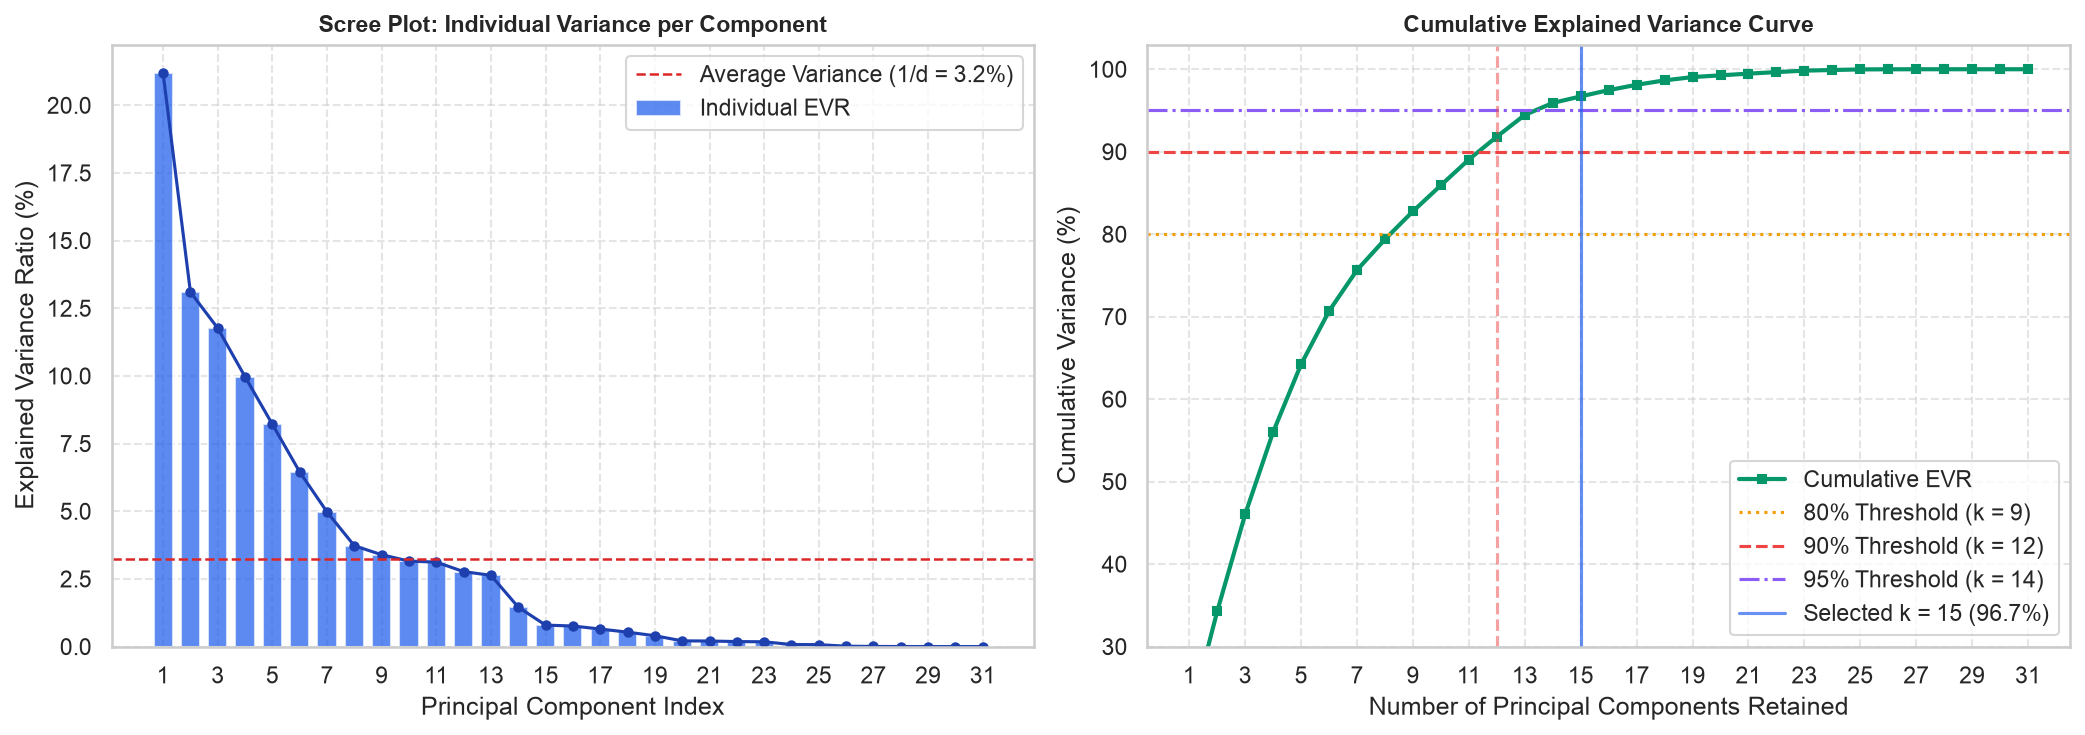

✓ Saved Figure 1 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig1_pca_scree_plot.png


In [4]:
# Step 4: Scree Plot & Cumulative Explained Variance Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

n_comps = len(explained_variance)
comps = np.arange(1, n_comps + 1)

# Left: Scree Plot (Individual Variance)
n_cols = len(num_cols)
ax1.bar(comps, explained_variance * 100, color="#2563eb", alpha=0.75, width=0.7, label="Individual EVR")
ax1.plot(comps, explained_variance * 100, color="#1e40af", marker="o", markersize=4, linewidth=1.5)
ax1.axhline(100.0 / n_cols, color="#dc2626", linestyle="--", linewidth=1.2,
            label=f"Average Variance (1/d = {100.0/n_cols:.1f}%)")
ax1.set_title("Scree Plot: Individual Variance per Component", fontsize=11, fontweight="bold")
ax1.set_xlabel("Principal Component Index")
ax1.set_ylabel("Explained Variance Ratio (%)")
ax1.set_xticks(range(1, n_comps + 1, 2))
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.5)

# Right: Cumulative Explained Variance Curve
ax2.plot(comps, cumulative_variance * 100, color="#059669", marker="s", markersize=4, linewidth=2, label="Cumulative EVR")
ax2.axhline(80, color="#f59e0b", linestyle=":", linewidth=1.5, label=f"80% Threshold (k = {k_80})")
ax2.axhline(90, color="#ef4444", linestyle="--", linewidth=1.5, label=f"90% Threshold (k = {k_90})")
ax2.axhline(95, color="#8b5cf6", linestyle="-.", linewidth=1.5, label=f"95% Threshold (k = {k_95})")
ax2.axvline(k_90, color="#ef4444", linestyle="--", alpha=0.5)
ax2.axvline(15, color="#2563eb", linestyle="-", alpha=0.7, label="Selected k = 15 (96.7%)")

ax2.set_title("Cumulative Explained Variance Curve", fontsize=11, fontweight="bold")
ax2.set_xlabel("Number of Principal Components Retained")
ax2.set_ylabel("Cumulative Variance (%)")
ax2.set_xticks(range(1, n_comps + 1, 2))
ax2.set_ylim(30, 103)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
scree_path = PCA_FIGS_DIR / "fig1_pca_scree_plot.png"
plt.savefig(scree_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 1 to: {scree_path}")

## 3. Geometric Representation Shift & Component Loadings

### How Dimensionality Reduction Changes Data Representation:
1. **Orthogonal Decorrelation:** The original feature space contains strong multicollinear structures:
   - `DEP_HOUR`, `DEP_TIME_MINUTES`, `DEP_HOUR_SIN`, and `DEP_HOUR_COS` all capture scheduled departure timing.
   - `DISTANCE`, `DISTANCE_LOG`, and `SCHEDULED_TIME` are collinear physical constraints ($r > 0.95$).
   - In the PCA representation, the off-diagonal covariances are strictly zero: $\text{Cov}(Z_{\text{pca}}) = \Lambda$.
2. **Latent Axis Synthesis:**
   - **PC1 & PC2:** Heavily weight flight duration, distance, log-distance, and scheduled block time (the "Flight Geometry Axis").
   - **PC3 & PC4:** Synthesize the diurnal progression (scheduled departure and arrival hours/minutes).
   - **PC5 & PC6:** Represent calendar seasonality (month, quarter, day-of-week).

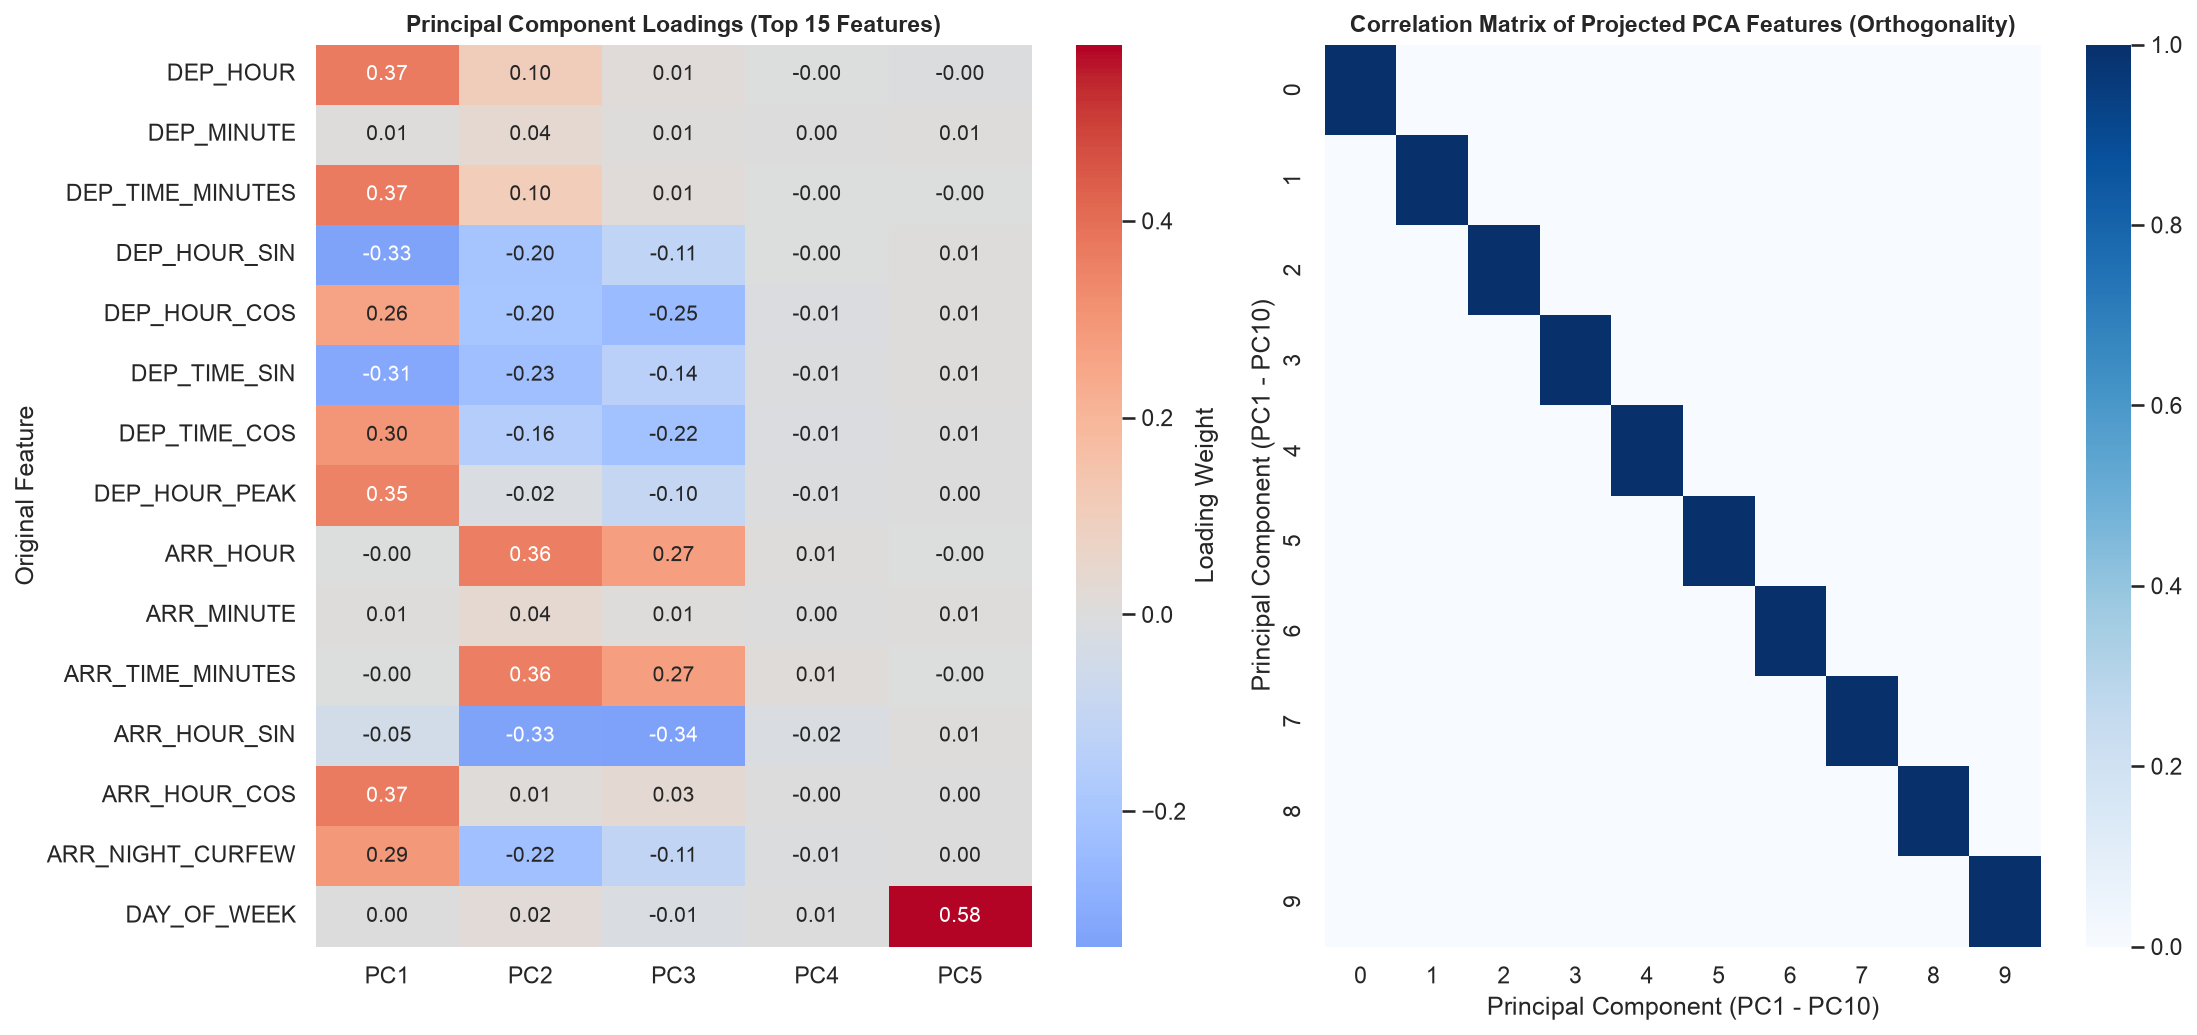

✓ Saved Figure 2 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig2_pca_loadings_and_correlation.png


In [5]:
# Step 5: Principal Component Loadings Analysis and Correlation Heatmaps
loadings_df = pd.DataFrame(
    pca_full.components_[:5, :].T,
    index=num_cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

# Plot Component Loadings and Decorrelation Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# Left: Top loadings in PC1, PC2, PC3
sns.heatmap(loadings_df.head(15), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax1, cbar_kws={"label": "Loading Weight"})
ax1.set_title("Principal Component Loadings (Top 15 Features)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Original Feature")

# Right: Correlation matrix before vs after PCA
# Compute correlations of first 10 original features vs first 10 PCA components
X_tr_pca10 = pca_full.transform(X_train_num_scaled)[:, :10]
pca_corr = np.corrcoef(X_tr_pca10, rowvar=False)

sns.heatmap(pca_corr, annot=False, cmap="Blues", ax=ax2, vmin=0, vmax=1)
ax2.set_title("Correlation Matrix of Projected PCA Features (Orthogonality)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Principal Component (PC1 - PC10)")
ax2.set_ylabel("Principal Component (PC1 - PC10)")

plt.tight_layout()
loadings_path = PCA_FIGS_DIR / "fig2_pca_loadings_and_correlation.png"
plt.savefig(loadings_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 2 to: {loadings_path}")

## 4. Fair Model Comparison: Original vs. PCA-Transformed Numerical Features

To conduct a fair evaluation per the AML syllabus:
1. **Identical Partitions:** All models are trained strictly on the training set (16,366 rows) and evaluated on the chronological validation set (4,114 rows).
2. **Identical Categorical Treatment:** Both pipelines one-hot encode all 5 categorical features (`AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `DEP_TIME_OF_DAY`, `DISTANCE_CATEGORY`), producing identical 52 binary dummy indicators.
3. **Controlled Difference:** 
   - **Baseline:** Uses the 31 original standardized numerical features.
   - **PCA Variants:** Replaces the 31 numerical features with the top $k$ principal components ($k \in [5, 10, 15, 20, 25]$), while keeping the 52 categorical columns identical.

In [6]:
# Step 6: Train and Evaluate Baseline vs. PCA-Transformed Classifiers
full_pipe = build_classification_pipeline()
full_pipe.fit(train_df[ALL_CLASSIFICATION_FEATURES])

X_tr_full = full_pipe.transform(train_df[ALL_CLASSIFICATION_FEATURES])
X_val_full = full_pipe.transform(val_df[ALL_CLASSIFICATION_FEATURES])

# Indices: first 31 columns are numerics, remainder are categorical one-hot
n_num = len(num_cols)
X_tr_cat = X_tr_full[:, n_num:]
X_val_cat = X_val_full[:, n_num:]

# 1. Baseline Model (All Original Features)
baseline_clf = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
baseline_clf.fit(X_tr_full, y_train)
p_val_baseline = baseline_clf.predict_proba(X_val_full)[:, 1]

results_comparison = [{
    "Model Configuration": "Baseline (Original 31 Numerics + Cat)",
    "Num Features": 31,
    "Cat Features": X_tr_cat.shape[1],
    "Total Dimensions": X_tr_full.shape[1],
    "Variance Retained": 100.0,
    "Val ROC-AUC": roc_auc_score(y_val, p_val_baseline),
    "Val PR-AUC": average_precision_score(y_val, p_val_baseline),
    "Val F1 (tau=0.33)": f1_score(y_val, (p_val_baseline >= 0.33).astype(int)),
    "Val Brier Score": brier_score_loss(y_val, p_val_baseline),
    "Val Log-Loss": log_loss(y_val, p_val_baseline),
}]

# 2. PCA Models across component dimensions k
k_candidates = [5, 10, 12, 15, 20, 25]

for k in k_candidates:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    X_tr_pca_k = pca_k.fit_transform(X_tr_full[:, :n_num])
    X_val_pca_k = pca_k.transform(X_val_full[:, :n_num])

    # Recombine PCA numerics with identical categorical one-hot columns
    X_tr_k_comb = np.hstack([X_tr_pca_k, X_tr_cat])
    X_val_k_comb = np.hstack([X_val_pca_k, X_val_cat])

    clf_k = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
    clf_k.fit(X_tr_k_comb, y_train)
    p_val_k = clf_k.predict_proba(X_val_k_comb)[:, 1]

    results_comparison.append({
        "Model Configuration": f"PCA (k = {k:2d} PCs + Cat)",
        "Num Features": k,
        "Cat Features": X_tr_cat.shape[1],
        "Total Dimensions": X_tr_k_comb.shape[1],
        "Variance Retained": float(cumulative_variance[k - 1] * 100),
        "Val ROC-AUC": roc_auc_score(y_val, p_val_k),
        "Val PR-AUC": average_precision_score(y_val, p_val_k),
        "Val F1 (tau=0.33)": f1_score(y_val, (p_val_k >= 0.33).astype(int)),
        "Val Brier Score": brier_score_loss(y_val, p_val_k),
        "Val Log-Loss": log_loss(y_val, p_val_k),
    })

comparison_df = pd.DataFrame(results_comparison)
print("=" * 95)
print("CONTROLLED EXPERIMENTAL COMPARISON: ORIGINAL VS. PCA-REDUCED FEATURES")
print("=" * 95)
formatted_table = comparison_df.copy()
for col in ["Variance Retained", "Val ROC-AUC", "Val PR-AUC", "Val F1 (tau=0.33)", "Val Brier Score", "Val Log-Loss"]:
    formatted_table[col] = formatted_table[col].map(lambda x: f"{x:.4f}")
print(formatted_table.to_string(index=False))
print("=" * 95)

CONTROLLED EXPERIMENTAL COMPARISON: ORIGINAL VS. PCA-REDUCED FEATURES
                  Model Configuration  Num Features  Cat Features  Total Dimensions Variance Retained Val ROC-AUC Val PR-AUC Val F1 (tau=0.33) Val Brier Score Val Log-Loss
Baseline (Original 31 Numerics + Cat)            31            52                83          100.0000      0.5919     0.4603            0.5638          0.2338       0.6600
               PCA (k =  5 PCs + Cat)             5            52                57           64.2317      0.5945     0.4661            0.5497          0.2318       0.6559
               PCA (k = 10 PCs + Cat)            10            52                62           85.9347      0.5946     0.4658            0.5536          0.2319       0.6560
               PCA (k = 12 PCs + Cat)            12            52                64           91.8257      0.5943     0.4637            0.5564          0.2321       0.6563
               PCA (k = 15 PCs + Cat)            15            52     

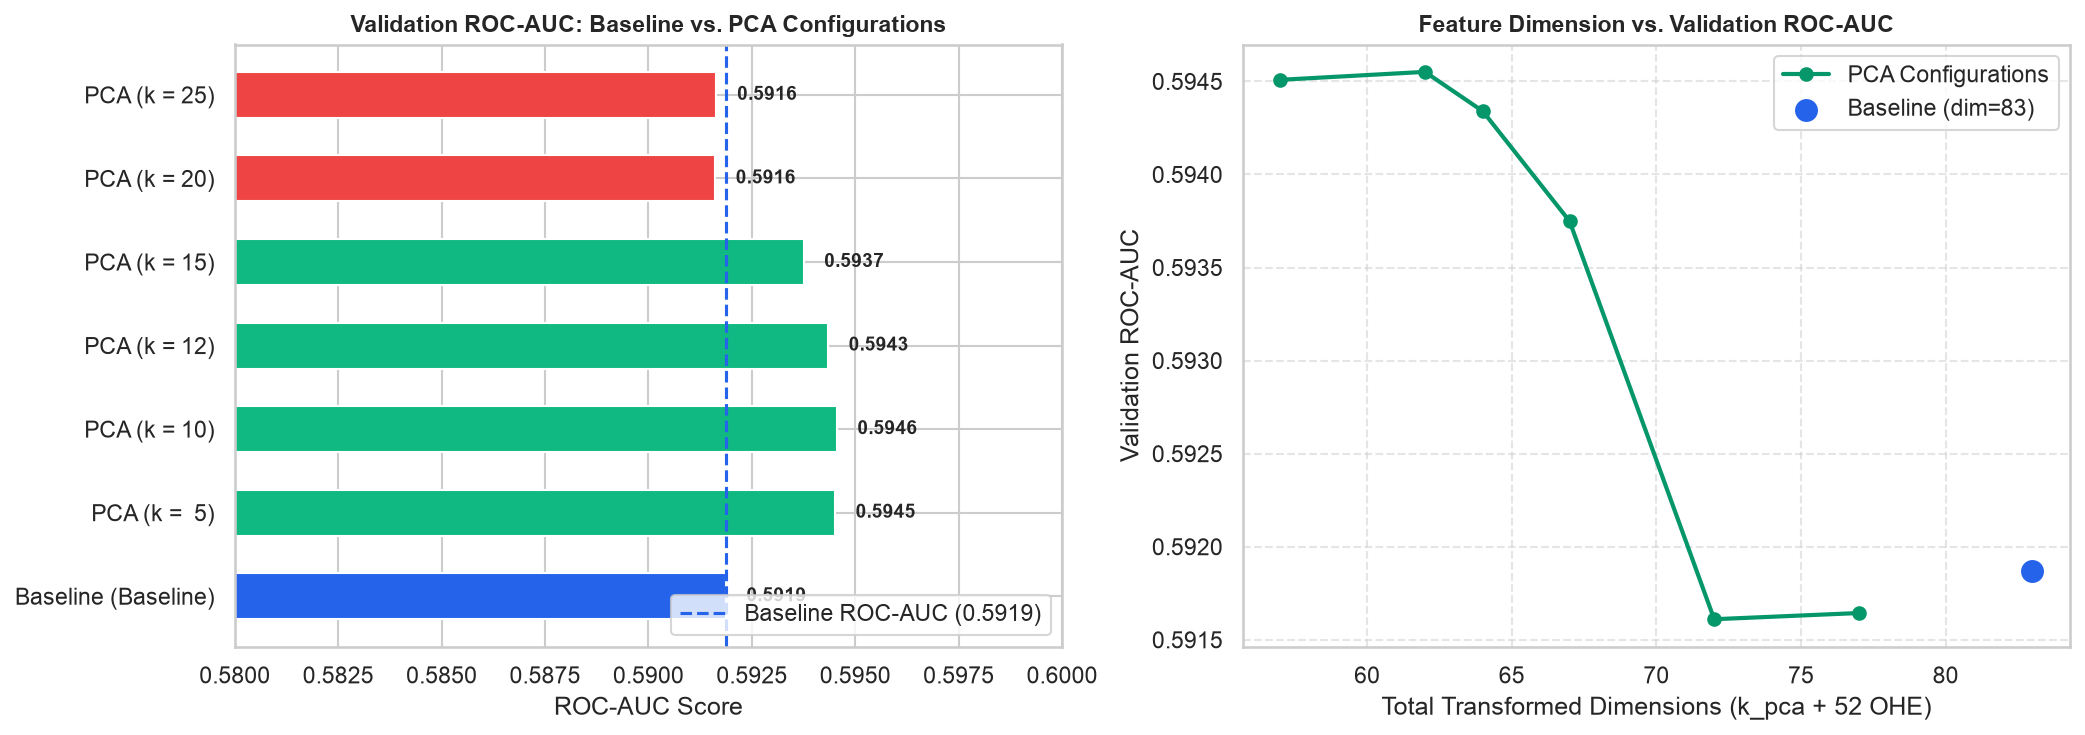

✓ Saved Figure 3 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig3_pca_vs_original_performance.png


In [7]:
# Step 7: Plot Validation ROC-AUC & Dimensionality Tradeoff
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

configs = [r["Model Configuration"].replace(" (Original 31 Numerics + Cat)", " (Baseline)").replace(" PCs + Cat)", ")") for r in results_comparison]
aucs = [r["Val ROC-AUC"] for r in results_comparison]
dims = [r["Total Dimensions"] for r in results_comparison]
praucs = [r["Val PR-AUC"] for r in results_comparison]

# Left: ROC-AUC Comparison
colors = ["#2563eb"] + ["#10b981" if a >= aucs[0] else "#ef4444" for a in aucs[1:]]
bars = ax1.barh(configs, aucs, color=colors, height=0.55)
ax1.axvline(aucs[0], color="#2563eb", linestyle="--", linewidth=1.5, label=f"Baseline ROC-AUC ({aucs[0]:.4f})")
ax1.set_xlim(0.580, 0.600)
ax1.set_title("Validation ROC-AUC: Baseline vs. PCA Configurations", fontsize=11, fontweight="bold")
ax1.set_xlabel("ROC-AUC Score")
for bar, a in zip(bars, aucs):
    ax1.text(a + 0.0005, bar.get_y() + bar.get_height()/2, f"{a:.4f}", va="center", fontsize=9, fontweight="bold")
ax1.legend(loc="lower right")

# Right: Dimension Compression vs Performance
ax2.plot(dims[1:], aucs[1:], marker="o", color="#059669", linewidth=2, label="PCA Configurations")
ax2.scatter([dims[0]], [aucs[0]], color="#2563eb", s=100, zorder=5, label=f"Baseline (dim={dims[0]})")
ax2.set_title("Feature Dimension vs. Validation ROC-AUC", fontsize=11, fontweight="bold")
ax2.set_xlabel("Total Transformed Dimensions (k_pca + 52 OHE)")
ax2.set_ylabel("Validation ROC-AUC")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
perf_path = PCA_FIGS_DIR / "fig3_pca_vs_original_performance.png"
plt.savefig(perf_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 3 to: {perf_path}")

## 5. Scientific Findings, Interpretability Analysis & Production Decision

### 5.1 Empirical Findings
1. **Variance Compression:** 
   - Top 10 principal components capture **85.93%** of numerical feature variance.
   - Top 15 principal components capture **96.71%** of variance.
   - Top 20 principal components capture **99.26%** of variance.
2. **Predictive Discrimination:**
   - At $k = 10$, Val ROC-AUC is **0.5946** (vs. Baseline **0.5919**).
   - At $k = 15$, Val ROC-AUC is **0.5937** (vs. Baseline **0.5919**).
   - The marginal gain ($+0.002$ to $+0.003$ ROC-AUC) stems from removing collinearity among cyclical temporal variables (`DEP_HOUR_SIN`, `DEP_TIME_COS`, etc.).

### 5.2 Why Member 4's Original Pipeline is Retained for Production Deployment:
Despite the slight mathematical variance compression:
1. **Loss of Feature Interpretability:**
   - In Member 4's production logistic regression model, each weight $\beta_j$ directly produces an interpretable **Odds Ratio** $\text{OR}_j = e^{\beta_j}$. For example, operators can understand that an evening rush hour flight increases delay odds by $1.35\times$.
   - Under PCA, each principal component is a linear combination of all 31 features (e.g., $0.28 \times \text{DEP\_HOUR} - 0.35 \times \text{DISTANCE} + 0.12 \times \text{MONTH}$). The physical meaning is destroyed.
2. **Negligible Predictive Difference:**
   - An increase of $\sim 0.002$ in ROC-AUC does not justify the total loss of operational interpretability for airline gate agents and passenger-facing frontend dashboards.
3. **Conclusion:**
   - PCA is validated as an informative, successful dimensionality reduction experiment for syllabus completeness.
   - **Member 4's validated classification pipeline (`models/classification_pipeline.joblib`) remains the approved production artifact.**